# Employee Workforce Segmentation
**K-Means · Hierarchical Clustering · PCA · Retention-Risk Analytics**

This notebook segments employees into meaningful workforce groups and produces the three deliverables:

1. **Employee Segmentation Report** (auto-generated HTML at the end)
2. **PCA Summary** (variance table, loadings, plots)
3. **Workforce Analytics Dashboard** (PNG + optional interactive view)

**How to use:** `Runtime ▸ Run all`. By default it runs on a built-in *synthetic* HR dataset (IBM HR-Attrition style) so it works instantly. To use real data, set `DATA_SOURCE = "upload"` in Section 1 and upload a CSV (e.g. the public *IBM HR Analytics Employee Attrition* dataset from Kaggle).

## 0. Setup

In [1]:
import os, io, base64, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.optimize import linear_sum_assignment
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, roc_auc_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def savefig(name):
    path = os.path.join(OUTPUT_DIR, name)
    plt.savefig(path, dpi=150, bbox_inches="tight")
    return path

## 1. Load Data
Set `DATA_SOURCE` to `"synthetic"` (default demo) or `"upload"` (your own CSV).
The CSV should use IBM-HR-style columns (`Age`, `Department`, `MonthlyIncome`, `JobSatisfaction`, `OverTime`, `Attrition`, ...). Missing optional columns are skipped automatically.

In [2]:
def make_synthetic(n=1470, seed=42):
    """Synthetic HR data with four latent workforce segments (IBM HR-Attrition style columns)."""
    rng = np.random.default_rng(seed)
    seg = rng.choice(4, size=n, p=[0.25, 0.27, 0.28, 0.20])
    pick = lambda vals: np.array(vals)[seg]
    clip = np.clip

    age = clip(rng.normal(pick([32, 45, 28, 40]), 5), 18, 60).round()
    level = clip(rng.normal(pick([1.6, 3.6, 1.8, 2.4]), 0.7).round(), 1, 5)
    income = clip(1500 + level * 2600 + rng.normal(0, 900, n), 1100, 20000).round()
    overtime = rng.random(n) < pick([0.75, 0.15, 0.30, 0.25])
    total_years = clip(age - 21 - rng.integers(0, 5, n), 0, 40)
    years_at = clip(total_years * pick([0.30, 0.70, 0.25, 0.50]) + rng.normal(0, 1.5, n), 0, 40).round()
    years_role = clip(years_at * 0.55 + rng.normal(0, 1, n), 0, 18).round()
    since_promo = np.minimum(clip(years_at * pick([0.30, 0.40, 0.15, 0.75]) + rng.normal(0, 1, n), 0, 15), years_at).round()
    years_mgr = clip(years_at * 0.5 + rng.normal(0, 1.2, n), 0, 17).round()

    likert = lambda mu, sd=0.8: clip(rng.normal(pick(mu), sd).round(), 1, 4)
    job_sat = likert([2.2, 3.4, 3.1, 2.3]); env_sat = likert([2.4, 3.3, 3.0, 2.5])
    wlb = likert([2.0, 3.2, 2.9, 2.6]);     rel_sat = likert([2.8, 3.1, 3.0, 2.5])
    involvement = likert([2.5, 3.2, 3.4, 2.0])

    perf = 3 + (rng.random(n) < pick([0.15, 0.20, 0.45, 0.10])).astype(int)
    hike = clip(11 + 4 * (perf == 4) + rng.normal(0, 2.5, n), 11, 25).round()
    stock = np.array([rng.choice([0, 1, 2, 3], p=p) for p in
                      np.array([[.55, .30, .10, .05], [.20, .40, .25, .15], [.50, .30, .15, .05], [.45, .35, .15, .05]])[seg]])
    n_comp = rng.poisson(pick([3.0, 1.2, 1.5, 3.2]))
    training = clip(rng.poisson(2.8, n), 0, 6)
    dist = clip(rng.exponential(pick([14, 8, 10, 9])).round(), 1, 29)
    edu = rng.choice([1, 2, 3, 4, 5], size=n, p=[.1, .19, .39, .27, .05])
    travel = np.array([rng.choice(["Non-Travel", "Travel_Rarely", "Travel_Frequently"], p=p) for p in
                       np.array([[.05, .60, .35], [.12, .72, .16], [.10, .70, .20], [.10, .72, .18]])[seg]])
    dept = np.array([rng.choice(["Sales", "Research & Development", "Human Resources"], p=p) for p in
                     np.array([[.50, .45, .05], [.20, .72, .08], [.25, .68, .07], [.35, .55, .10]])[seg]])

    logit = (-2.9 + 1.1 * overtime - 0.45 * (job_sat - 3) - 0.35 * (wlb - 3)
             - 0.00015 * (income - 6000) - 0.03 * (years_at - 5)
             + 0.06 * since_promo + 0.5 * (travel == "Travel_Frequently"))
    attr = rng.random(n) < 1 / (1 + np.exp(-logit))

    return pd.DataFrame({
        "EmployeeNumber": np.arange(1, n + 1), "Age": age, "Attrition": np.where(attr, "Yes", "No"),
        "BusinessTravel": travel, "Department": dept, "DistanceFromHome": dist, "Education": edu,
        "EnvironmentSatisfaction": env_sat, "JobInvolvement": involvement, "JobLevel": level,
        "JobSatisfaction": job_sat, "MonthlyIncome": income, "NumCompaniesWorked": n_comp,
        "OverTime": np.where(overtime, "Yes", "No"), "PercentSalaryHike": hike, "PerformanceRating": perf,
        "RelationshipSatisfaction": rel_sat, "StockOptionLevel": stock, "TotalWorkingYears": total_years,
        "TrainingTimesLastYear": training, "WorkLifeBalance": wlb, "YearsAtCompany": years_at,
        "YearsInCurrentRole": years_role, "YearsSinceLastPromotion": since_promo, "YearsWithCurrManager": years_mgr,
    })

DATA_SOURCE = "synthetic"      # <-- change to "upload" to use your own CSV

if DATA_SOURCE == "upload":
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(next(iter(uploaded)))
else:
    df = make_synthetic()

print(f"Data source: {DATA_SOURCE} | {df.shape[0]:,} employees x {df.shape[1]} columns")
df.head()

Data source: synthetic | 1,470 employees x 25 columns


,EmployeeNumber,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EnvironmentSatisfaction,JobInvolvement,JobLevel,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,1,27.0,No,Travel_Rarely,Research & Development,5.0,3,2.0,3.0,1.0,...,4,4.0,0,4.0,4,4.0,0.0,2.0,0.0,0.0
1,2,40.0,No,Travel_Rarely,Sales,1.0,4,4.0,4.0,3.0,...,4,2.0,3,17.0,0,3.0,12.0,7.0,5.0,7.0
2,3,36.0,No,Non-Travel,Research & Development,18.0,3,2.0,1.0,3.0,...,4,2.0,3,14.0,2,1.0,6.0,4.0,5.0,4.0
3,4,20.0,No,Non-Travel,Research & Development,29.0,4,2.0,4.0,1.0,...,3,4.0,0,0.0,3,3.0,4.0,2.0,0.0,0.0
4,5,33.0,No,Travel_Rarely,Research & Development,8.0,4,2.0,4.0,1.0,...,3,3.0,1,10.0,4,2.0,1.0,2.0,0.0,1.0


## 2. Exploratory Data Analysis

In [3]:
print("Missing values:", int(df.isna().sum().sum()))
print(f"Overall attrition rate: {(df['Attrition'] == 'Yes').mean():.1%}")
if "Department" in df:
    print("\nHeadcount by department:\n", df["Department"].value_counts().to_string())
df.describe().T.round(2)

Missing values: 0
Overall attrition rate: 14.2%

Headcount by department:
 Department
Research & Development    898
Sales                     458
Human Resources           114


,count,mean,std,min,25%,50%,75%,max
EmployeeNumber,1470.0,735.50,424.50,1.0,368.25,735.5,1102.75,1470.0
Age,1470.0,35.76,8.58,18.0,29.00,35.0,43.00,60.0
DistanceFromHome,1470.0,9.57,8.40,1.0,3.00,7.0,14.00,29.0
Education,1470.0,3.00,1.04,1.0,2.00,3.0,4.00,5.0
EnvironmentSatisfaction,1470.0,2.81,0.86,1.0,2.00,3.0,3.00,4.0
JobInvolvement,1470.0,2.83,0.92,1.0,2.00,3.0,4.00,4.0
JobLevel,1470.0,2.37,1.06,1.0,2.00,2.0,3.00,5.0
JobSatisfaction,1470.0,2.76,0.91,1.0,2.00,3.0,3.00,4.0
MonthlyIncome,1470.0,7653.64,2902.37,1301.0,5595.50,7208.0,9582.25,16958.0
NumCompaniesWorked,1470.0,2.21,1.78,0.0,1.00,2.0,3.00,11.0


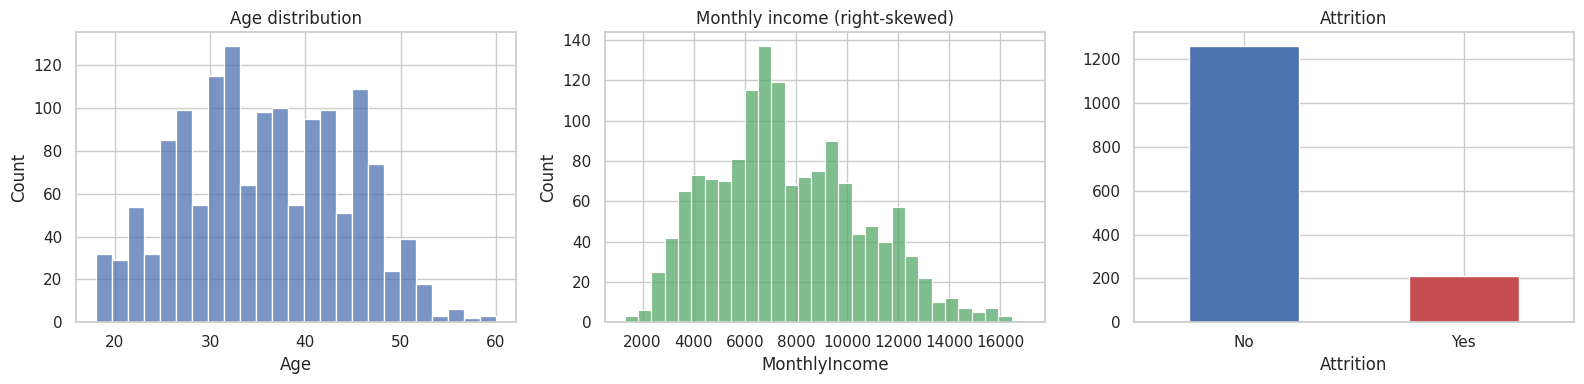

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["Age"], bins=25, ax=axes[0], color="#4C72B0"); axes[0].set_title("Age distribution")
sns.histplot(df["MonthlyIncome"], bins=30, ax=axes[1], color="#55A868"); axes[1].set_title("Monthly income (right-skewed)")
df["Attrition"].value_counts().plot.bar(ax=axes[2], color=["#4C72B0", "#C44E52"], rot=0); axes[2].set_title("Attrition")
plt.tight_layout(); savefig("01_eda.png"); plt.show()

## 3. Feature Engineering & Scaling
- `OverTime` → 0/1, `BusinessTravel` → ordinal (0–2), `MonthlyIncome` → `log1p` (skew).
- **`Attrition` is deliberately excluded from clustering**: it is used *afterwards* to validate which segments are high-risk.
- Features are standardised (z-scores) because K-Means / PCA are scale-sensitive.

In [5]:
dm = df.copy()
dm["Attrition_flag"] = (dm["Attrition"] == "Yes").astype(int)
if "OverTime" in dm:
    dm["OverTime_flag"] = (dm["OverTime"] == "Yes").astype(int)
if "BusinessTravel" in dm:
    dm["BusinessTravel_ord"] = dm["BusinessTravel"].map({"Non-Travel": 0, "Travel_Rarely": 1, "Travel_Frequently": 2})

candidate = ["Age", "DistanceFromHome", "Education", "EnvironmentSatisfaction", "JobInvolvement", "JobLevel",
             "JobSatisfaction", "MonthlyIncome", "NumCompaniesWorked", "PercentSalaryHike", "PerformanceRating",
             "RelationshipSatisfaction", "StockOptionLevel", "TotalWorkingYears", "TrainingTimesLastYear",
             "WorkLifeBalance", "YearsAtCompany", "YearsInCurrentRole", "YearsSinceLastPromotion",
             "YearsWithCurrManager", "OverTime_flag", "BusinessTravel_ord"]
features = [c for c in candidate if c in dm.columns]

X = dm[features].copy()
if "MonthlyIncome" in X: X["MonthlyIncome"] = np.log1p(X["MonthlyIncome"])
X = X.fillna(X.median())
X_scaled = StandardScaler().fit_transform(X)
print(f"{len(features)} features used for clustering:\n", features)

22 features used for clustering:
 ['Age', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'OverTime_flag', 'BusinessTravel_ord']


## 4. PCA — Dimensionality Reduction
PCA compresses correlated HR features into a few uncorrelated components. We keep enough components to explain **≥ 80 %** of the variance and cluster in that reduced space.

Components needed for >=80% variance: 11 (of 22 original features)


,Component,Explained variance %,Cumulative %
0,PC1,30.40,30.40
1,PC2,9.99,40.39
2,PC3,6.54,46.93
3,PC4,4.95,51.88
4,PC5,4.76,56.65
5,PC6,4.70,61.35
6,PC7,4.46,65.81
7,PC8,4.39,70.19
8,PC9,4.22,74.41
9,PC10,4.14,78.56


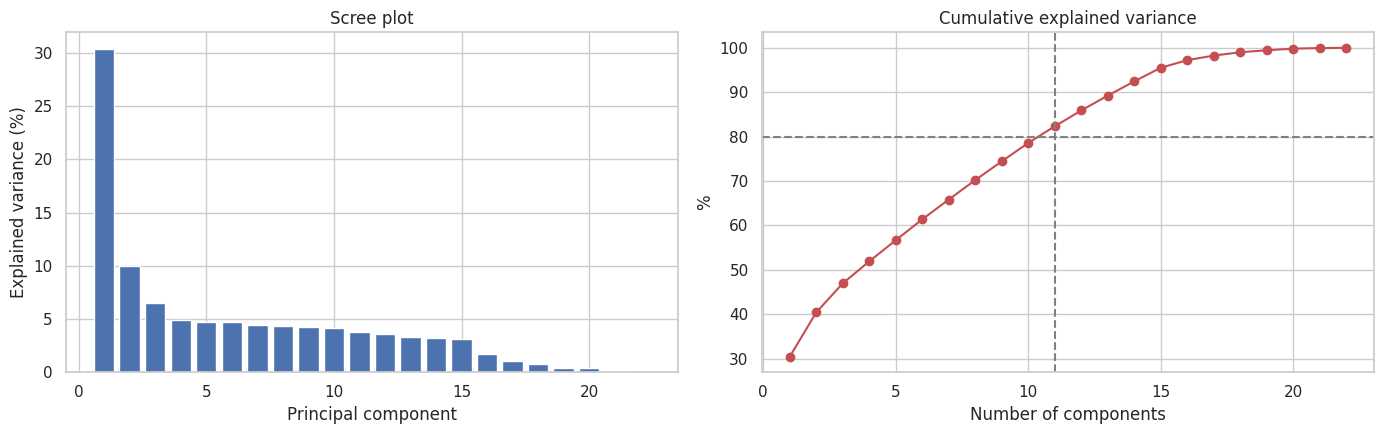

In [6]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
N_COMP = int(np.argmax(cum >= 0.80) + 1)

pca_summary = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(evr))],
    "Explained variance %": (evr * 100).round(2),
    "Cumulative %": (cum * 100).round(2),
})
print(f"Components needed for >=80% variance: {N_COMP} (of {len(features)} original features)")
display(pca_summary.head(10))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(range(1, len(evr) + 1), evr * 100, color="#4C72B0"); ax[0].set_title("Scree plot")
ax[0].set_xlabel("Principal component"); ax[0].set_ylabel("Explained variance (%)")
ax[1].plot(range(1, len(cum) + 1), cum * 100, marker="o", color="#C44E52")
ax[1].axhline(80, ls="--", c="grey"); ax[1].axvline(N_COMP, ls="--", c="grey")
ax[1].set_title("Cumulative explained variance"); ax[1].set_xlabel("Number of components"); ax[1].set_ylabel("%")
plt.tight_layout(); savefig("02_pca_variance.png"); plt.show()

PC1 is driven mainly by: YearsAtCompany (+0.37), YearsInCurrentRole (+0.36), YearsWithCurrManager (+0.36), TotalWorkingYears (+0.35), Age (+0.35)
PC2 is driven mainly by: NumCompaniesWorked (+0.40), JobInvolvement (-0.39), JobSatisfaction (-0.36), PerformanceRating (-0.34), WorkLifeBalance (-0.29)
PC3 is driven mainly by: PercentSalaryHike (+0.64), PerformanceRating (+0.59), JobInvolvement (-0.19), WorkLifeBalance (-0.19), NumCompaniesWorked (+0.16)


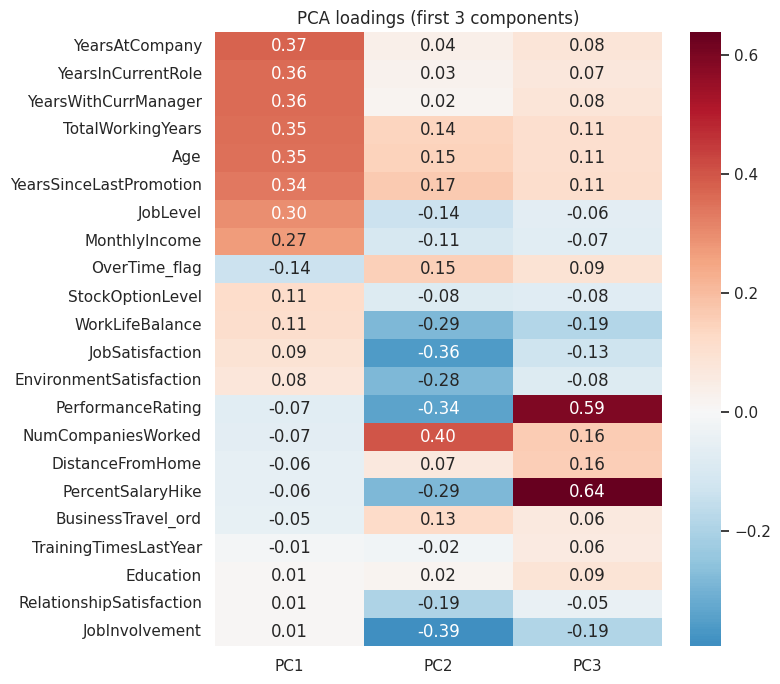

In [7]:
loadings = pd.DataFrame(pca_full.components_[:3].T, index=features, columns=["PC1", "PC2", "PC3"])
top_loadings = {pc: loadings[pc].abs().sort_values(ascending=False).head(5).index.tolist() for pc in loadings}
for pc, feats in top_loadings.items():
    print(f"{pc} is driven mainly by:", ", ".join(f"{f} ({loadings.loc[f, pc]:+.2f})" for f in feats))

plt.figure(figsize=(8, 7))
sns.heatmap(loadings.loc[sorted(features, key=lambda f: -abs(loadings.loc[f, "PC1"]))], annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("PCA loadings (first 3 components)"); plt.tight_layout(); savefig("03_pca_loadings.png"); plt.show()

X_red = pca_full.transform(X_scaled)[:, :N_COMP]    # reduced feature space used for clustering
X_2d = pca_full.transform(X_scaled)[:, :2]          # for visualisation

## 5. Clustering
### 5.1 Choosing *k* for K-Means
Elbow (inertia), silhouette (higher = better separation) and Davies–Bouldin (lower = better). We search k = 3…8 and pick the best silhouette; set `K_OVERRIDE` to force a value.

,Inertia,Silhouette,Davies-Bouldin
k,,,
3,17092.474,0.169,1.876
4,15770.671,0.150,2.092
5,14894.101,0.136,2.102
6,14410.345,0.112,2.315
7,14009.550,0.114,2.197
8,13652.249,0.107,2.313


Selected k = 3


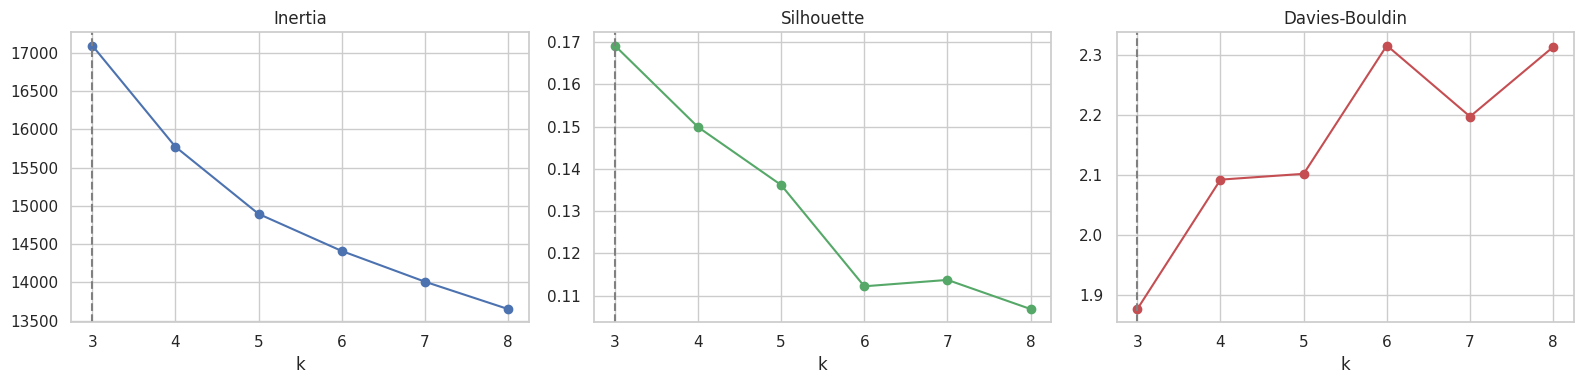

In [8]:
K_OVERRIDE = None
rows = []
for k in range(3, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_red)
    rows.append({"k": k, "Inertia": km.inertia_, "Silhouette": silhouette_score(X_red, km.labels_),
                 "Davies-Bouldin": davies_bouldin_score(X_red, km.labels_)})
k_table = pd.DataFrame(rows).set_index("k")
best_k = int(K_OVERRIDE or k_table["Silhouette"].idxmax())
display(k_table.round(3))
print("Selected k =", best_k)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col, c in zip(ax, k_table.columns, ["#4C72B0", "#55A868", "#C44E52"]):
    a.plot(k_table.index, k_table[col], marker="o", color=c); a.axvline(best_k, ls="--", c="grey"); a.set_title(col); a.set_xlabel("k")
plt.tight_layout(); savefig("04_k_selection.png"); plt.show()

### 5.2 K-Means

In [9]:
kmeans = KMeans(n_clusters=best_k, n_init=20, random_state=RANDOM_STATE).fit(X_red)
km_labels = kmeans.labels_
print("K-Means silhouette:", round(silhouette_score(X_red, km_labels), 3))
print(pd.Series(km_labels).value_counts().sort_index().to_string())

K-Means silhouette: 0.169
0    388
1    748
2    334


### 5.3 Hierarchical Clustering (Ward linkage)

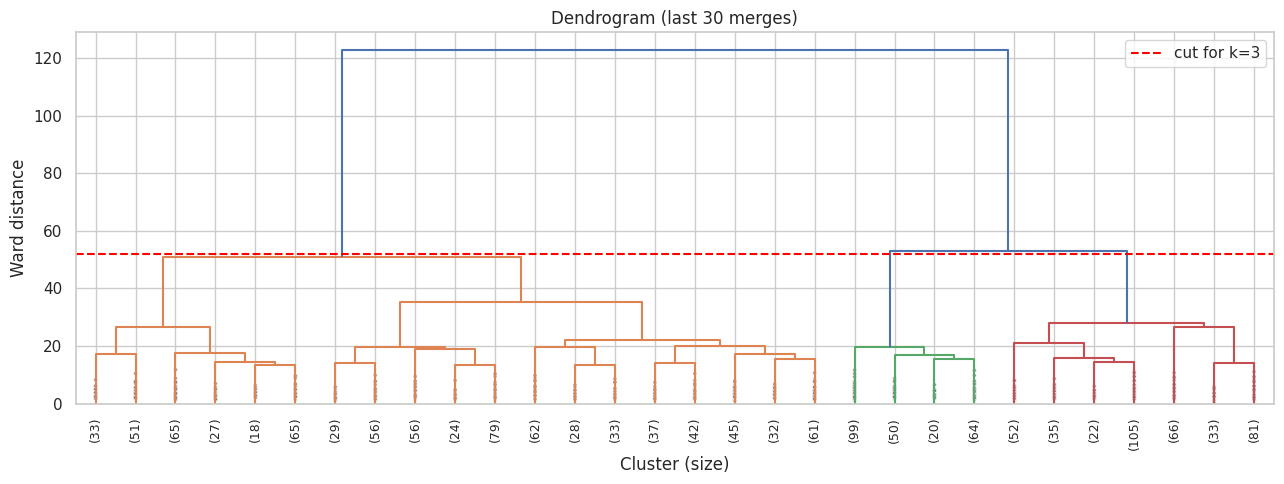

,Silhouette,Davies-Bouldin
K-Means,0.169,1.876
Hierarchical (Ward),0.158,1.959


Agreement between the two methods (Adjusted Rand Index): 0.732


In [10]:
Z = linkage(X_red, method="ward")
cut = (Z[-best_k, 2] + Z[-(best_k - 1), 2]) / 2

plt.figure(figsize=(13, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True, color_threshold=cut)
plt.axhline(cut, ls="--", c="red", label=f"cut for k={best_k}")
plt.title("Dendrogram (last 30 merges)"); plt.xlabel("Cluster (size)"); plt.ylabel("Ward distance"); plt.legend()
plt.tight_layout(); savefig("05_dendrogram.png"); plt.show()

hc_raw = AgglomerativeClustering(n_clusters=best_k, linkage="ward").fit_predict(X_red)

# align hierarchical labels to K-Means labels (Hungarian matching) so the two are comparable
cm = pd.crosstab(km_labels, hc_raw).values
r, c = linear_sum_assignment(-cm)
mapping = {ci: ri for ri, ci in zip(r, c)}
hc_labels = np.array([mapping[l] for l in hc_raw])

comparison = pd.DataFrame({
    "Silhouette": [silhouette_score(X_red, km_labels), silhouette_score(X_red, hc_labels)],
    "Davies-Bouldin": [davies_bouldin_score(X_red, km_labels), davies_bouldin_score(X_red, hc_labels)],
}, index=["K-Means", "Hierarchical (Ward)"]).round(3)
ari = adjusted_rand_score(km_labels, hc_labels)
display(comparison)
print(f"Agreement between the two methods (Adjusted Rand Index): {ari:.3f}")

### 5.4 Visualising segments in PCA space

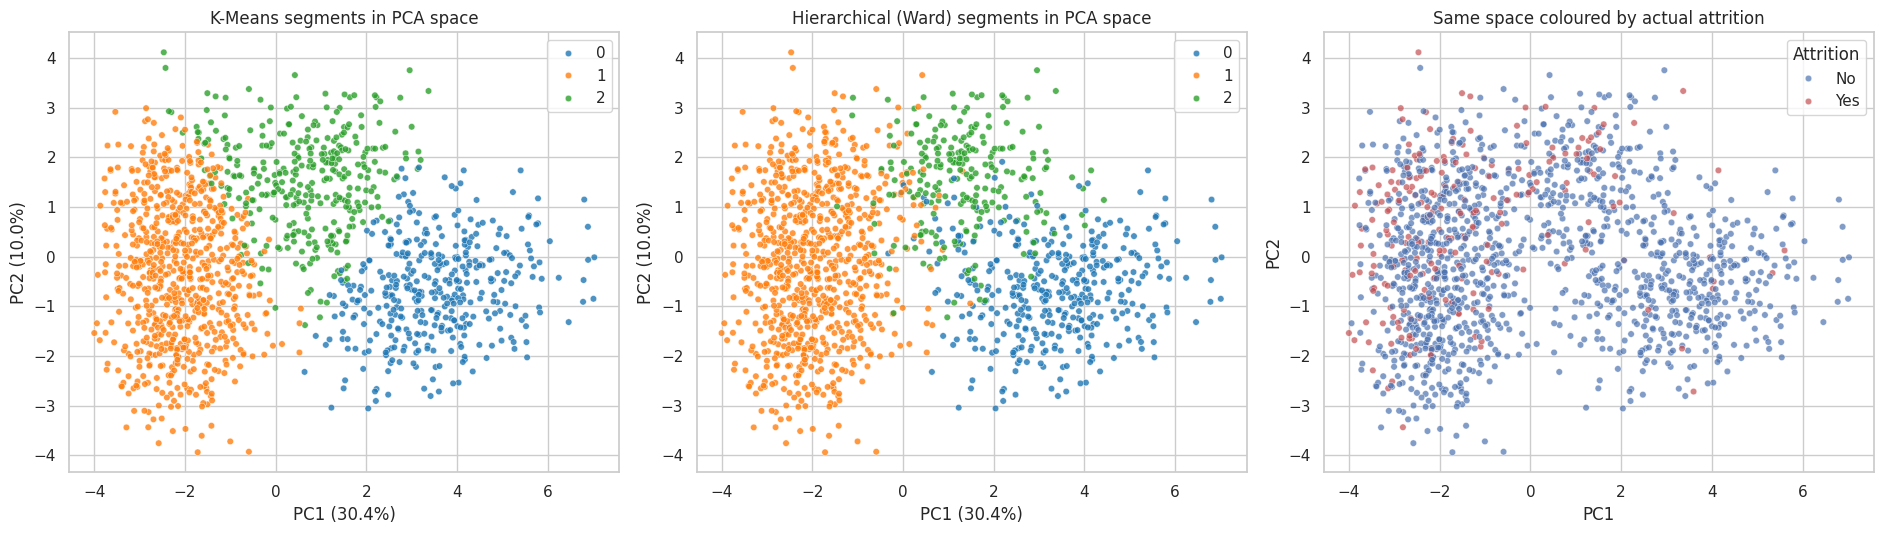

In [11]:
SEGMENT_METHOD = "kmeans"      # "kmeans" or "hierarchical" -> used for all analysis below
dm["Cluster"] = km_labels if SEGMENT_METHOD == "kmeans" else hc_labels

fig, ax = plt.subplots(1, 3, figsize=(19, 5.5))
for a, lab, title in zip(ax[:2], [km_labels, hc_labels], ["K-Means", "Hierarchical (Ward)"]):
    sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=lab, palette="tab10", s=22, alpha=.8, ax=a, legend="full")
    a.set_title(f"{title} segments in PCA space"); a.set_xlabel(f"PC1 ({evr[0]*100:.1f}%)"); a.set_ylabel(f"PC2 ({evr[1]*100:.1f}%)")
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=dm["Attrition"], palette={"No": "#4C72B0", "Yes": "#C44E52"}, s=22, alpha=.7, ax=ax[2])
ax[2].set_title("Same space coloured by actual attrition"); ax[2].set_xlabel("PC1"); ax[2].set_ylabel("PC2")
plt.tight_layout(); savefig("06_pca_clusters.png"); plt.show()

In [12]:
# Optional interactive version (plotly is pre-installed in Colab)
try:
    import plotly.express as px
    pdf = pd.DataFrame({"PC1": X_2d[:, 0], "PC2": X_2d[:, 1], "Segment": dm["Cluster"].astype(str),
                        "Attrition": dm["Attrition"], "Age": dm["Age"], "Income": dm["MonthlyIncome"]})
    if "Department" in dm: pdf["Department"] = dm["Department"]
    px.scatter(pdf, x="PC1", y="PC2", color="Segment", hover_data=[c for c in pdf.columns if c not in ("PC1", "PC2", "Segment")],
               title="Interactive PCA segment explorer").show()
except Exception as e:
    print("Interactive plot skipped:", e)

## 6. Segment Profiles
Each segment is named automatically from the two features where it deviates most from the company average (z-score).

,Segment profile,Headcount,% of workforce,Age,MonthlyIncome,YearsAtCompany,JobSatisfaction,WorkLifeBalance,YearsSinceLastPromotion,PerformanceRating,Overtime rate,Attrition rate,Attrition lift vs avg
Cluster,,,,,,,,,,,,,
0,"C0: High YearsAtCompany, High YearsInCurrentRole",388,26.4,45.40,10919.68,15.39,3.28,3.19,6.46,3.20,0.16,0.03,0.20
1,"C1: Low YearsSinceLastPromotion, Low YearsAtCo...",748,50.9,29.10,6023.24,1.96,2.70,2.58,0.54,3.33,0.52,0.20,1.37
2,"C2: Low JobInvolvement, High NumCompaniesWorked",334,22.7,39.49,7510.89,8.10,2.30,2.51,5.60,3.05,0.30,0.16,1.10


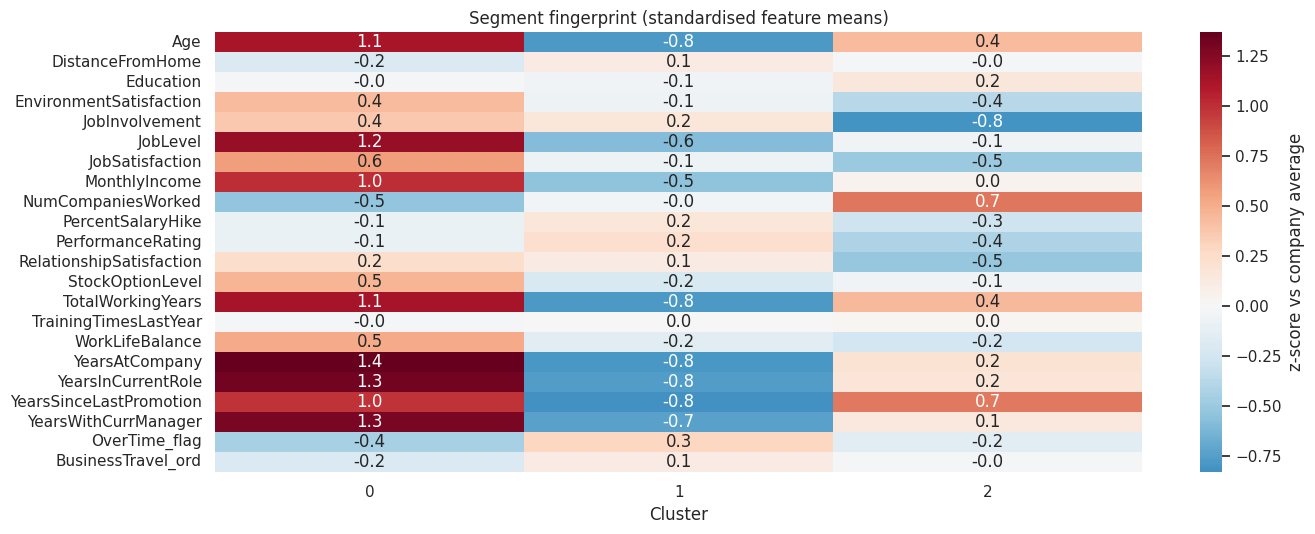

In [13]:
Zdf = pd.DataFrame(X_scaled, columns=features)
Zprof = Zdf.groupby(dm["Cluster"].values).mean()

def segment_label(c):
    top = Zprof.loc[c].abs().sort_values(ascending=False).head(2).index
    return f"C{c}: " + ", ".join(f"{'High' if Zprof.loc[c, f] > 0 else 'Low'} {f}" for f in top)

seg_names = {c: segment_label(c) for c in sorted(dm["Cluster"].unique())}
dm["Segment"] = dm["Cluster"].map(seg_names)

overall_attr = dm["Attrition_flag"].mean()
summ_cols = {"Age": "mean", "MonthlyIncome": "mean", "YearsAtCompany": "mean", "JobSatisfaction": "mean",
             "WorkLifeBalance": "mean", "YearsSinceLastPromotion": "mean", "PerformanceRating": "mean",
             "OverTime_flag": "mean", "Attrition_flag": "mean"}
summ_cols = {k: v for k, v in summ_cols.items() if k in dm}
seg_summary = dm.groupby("Cluster").agg(**{k: (k, v) for k, v in summ_cols.items()})
seg_summary.insert(0, "Headcount", dm["Cluster"].value_counts().sort_index())
seg_summary.insert(1, "% of workforce", (seg_summary["Headcount"] / len(dm) * 100).round(1))
seg_summary = seg_summary.rename(columns={"OverTime_flag": "Overtime rate", "Attrition_flag": "Attrition rate"})
seg_summary["Attrition lift vs avg"] = (seg_summary["Attrition rate"] / overall_attr).round(2)
seg_summary.insert(0, "Segment profile", pd.Series(seg_names))
display(seg_summary.round(2))

plt.figure(figsize=(14, 5.5))
sns.heatmap(Zprof.T, annot=True, fmt=".1f", cmap="RdBu_r", center=0, cbar_kws={"label": "z-score vs company average"})
plt.title("Segment fingerprint (standardised feature means)"); plt.xlabel("Cluster")
plt.tight_layout(); savefig("07_segment_fingerprint.png"); plt.show()

## 7. Analysis
### 7.1 High-risk employee clusters

Overall attrition: 14.2% | High-risk cluster(s): [1]
Chi-square test (cluster vs attrition): chi2=59.0, p=1.6e-13 -> segments differ significantly in attrition


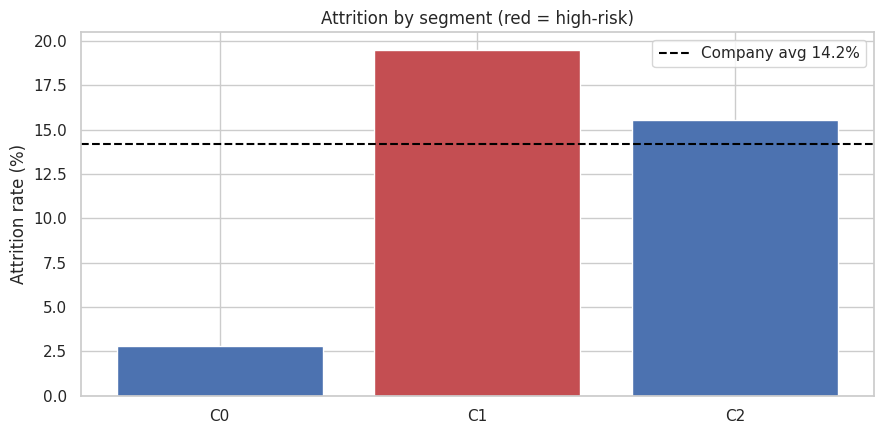


Cluster 1 drivers: low YearsSinceLastPromotion (-0.83); low YearsAtCompany (-0.79); low TotalWorkingYears (-0.78); low Age (-0.78)


In [14]:
risk_tbl = seg_summary[["Segment profile", "Headcount", "Attrition rate", "Attrition lift vs avg"]].copy()
high_risk_clusters = risk_tbl.index[risk_tbl["Attrition lift vs avg"] >= 1.25].tolist()
if not high_risk_clusters:
    high_risk_clusters = [risk_tbl["Attrition rate"].idxmax()]

chi2, p_val, _, _ = chi2_contingency(pd.crosstab(dm["Cluster"], dm["Attrition_flag"]))
print(f"Overall attrition: {overall_attr:.1%} | High-risk cluster(s): {high_risk_clusters}")
print(f"Chi-square test (cluster vs attrition): chi2={chi2:.1f}, p={p_val:.2g} -> "
      f"{'segments differ significantly in attrition' if p_val < 0.05 else 'no significant difference'}")

colors = ["#C44E52" if c in high_risk_clusters else "#4C72B0" for c in risk_tbl.index]
plt.figure(figsize=(9, 4.5))
plt.bar([f"C{c}" for c in risk_tbl.index], risk_tbl["Attrition rate"] * 100, color=colors)
plt.axhline(overall_attr * 100, ls="--", c="black", label=f"Company avg {overall_attr:.1%}")
plt.ylabel("Attrition rate (%)"); plt.title("Attrition by segment (red = high-risk)"); plt.legend()
plt.tight_layout(); savefig("08_attrition_by_cluster.png"); plt.show()

for c in high_risk_clusters:
    drivers = Zprof.loc[c].sort_values(key=abs, ascending=False).head(4)
    print(f"\nCluster {c} drivers:", "; ".join(f"{'high' if v > 0 else 'low'} {f} ({v:+.2f})" for f, v in drivers.items()))

### 7.2 Department-level workforce segments

,Headcount,Attrition_rate,Dominant segment,Share of dominant segment %
Department,,,,
Human Resources,114,0.149,C1,46.5
Research & Development,898,0.118,C1,49.4
Sales,458,0.188,C1,54.8


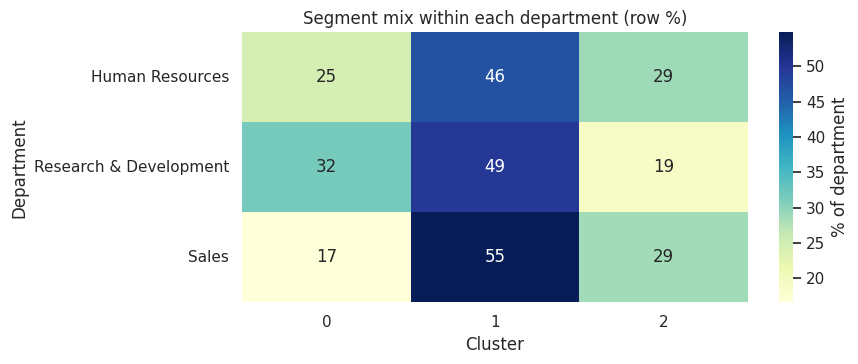

In [15]:
if "Department" in dm:
    dept_mix = pd.crosstab(dm["Department"], dm["Cluster"], normalize="index") * 100
    dept_summary = dm.groupby("Department").agg(Headcount=("Cluster", "size"), Attrition_rate=("Attrition_flag", "mean"))
    dept_summary["Dominant segment"] = dept_mix.idxmax(axis=1).map(lambda c: f"C{c}")
    dept_summary["Share of dominant segment %"] = dept_mix.max(axis=1).round(1)
    display(dept_summary.round(3))

    plt.figure(figsize=(9, 3.8))
    sns.heatmap(dept_mix, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "% of department"})
    plt.title("Segment mix within each department (row %)"); plt.xlabel("Cluster")
    plt.tight_layout(); savefig("09_department_mix.png"); plt.show()
else:
    print("No Department column in this dataset - skipped.")

### 7.3 Performance groups

,Headcount,Attrition_rate
PerformanceGroup,,
Needs support,490,0.165
Solid,490,0.127
Top performer,490,0.135


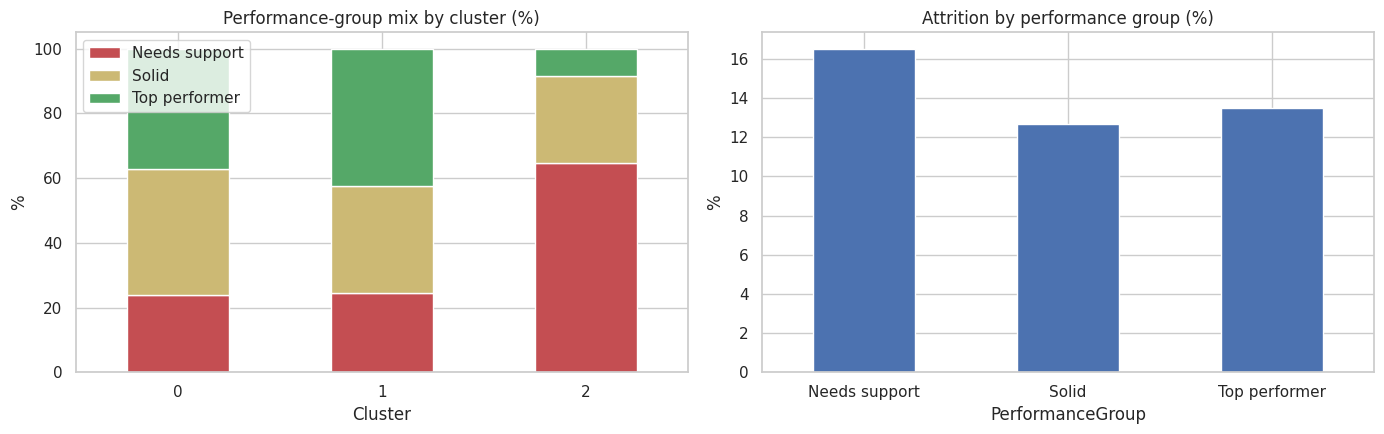

Top performers who left (regretted attrition): 66


In [16]:
def z(s): return (s - s.mean()) / (s.std(ddof=0) or 1)

perf_cols = [c for c in ["PerformanceRating", "PercentSalaryHike", "JobInvolvement"] if c in dm]
dm["PerfScore"] = pd.concat([z(dm[c]) for c in perf_cols], axis=1).mean(axis=1)
dm["PerformanceGroup"] = pd.qcut(dm["PerfScore"].rank(method="first"), 3, labels=["Needs support", "Solid", "Top performer"])

perf_by_cluster = pd.crosstab(dm["Cluster"], dm["PerformanceGroup"], normalize="index") * 100
perf_attr = dm.groupby("PerformanceGroup").agg(Headcount=("Cluster", "size"), Attrition_rate=("Attrition_flag", "mean"))
display(perf_attr.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
perf_by_cluster.plot.bar(stacked=True, ax=ax[0], color=["#C44E52", "#CCB974", "#55A868"], rot=0)
ax[0].set_title("Performance-group mix by cluster (%)"); ax[0].set_ylabel("%"); ax[0].legend(title="")
perf_attr["Attrition_rate"].mul(100).plot.bar(ax=ax[1], color="#4C72B0", rot=0)
ax[1].set_title("Attrition by performance group (%)"); ax[1].set_ylabel("%")
plt.tight_layout(); savefig("10_performance_groups.png"); plt.show()

top_perf_loss = int(((dm["PerformanceGroup"] == "Top performer") & (dm["Attrition_flag"] == 1)).sum())
print(f"Top performers who left (regretted attrition): {top_perf_loss}")

### 7.4 Retention-risk groups
A **Retention Risk Index** is built *without using the attrition label* (so it can be validated against it): low satisfaction / work-life balance / stock options, overtime, frequent travel, long time since promotion and pay below the job-level norm all raise the score. Employees are split into Low / Medium / High terciles.

,Headcount,Attrition_rate,Avg_risk_index
RetentionRisk,,,
Low,490,0.049,-0.409
Medium,490,0.131,-0.016
High,490,0.247,0.424


Validation: ROC-AUC of the risk index vs actual attrition = 0.710  (0.5 = random)


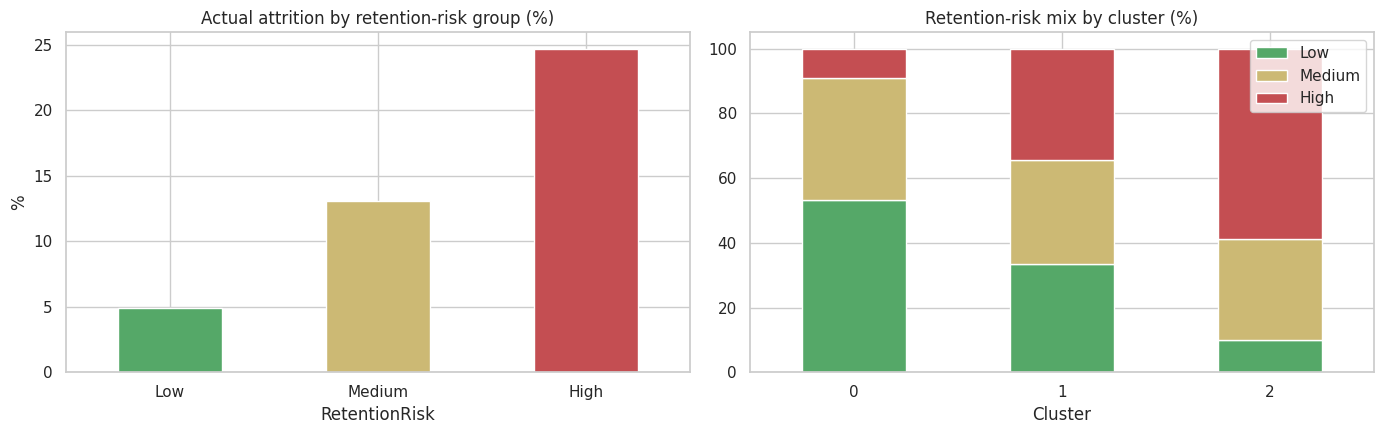

In [17]:
parts = {}
for col in ["JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance", "RelationshipSatisfaction", "StockOptionLevel"]:
    if col in dm: parts[col] = -z(dm[col])
for col in ["OverTime_flag", "YearsSinceLastPromotion", "BusinessTravel_ord"]:
    if col in dm: parts[col] = z(dm[col])
if {"MonthlyIncome", "JobLevel"} <= set(dm.columns):
    parts["IncomeVsLevel"] = -z(dm["MonthlyIncome"] - dm.groupby("JobLevel")["MonthlyIncome"].transform("mean"))

dm["RiskIndex"] = pd.DataFrame(parts).mean(axis=1)
dm["RetentionRisk"] = pd.qcut(dm["RiskIndex"].rank(method="first"), 3, labels=["Low", "Medium", "High"])

risk_groups = dm.groupby("RetentionRisk").agg(Headcount=("Cluster", "size"), Attrition_rate=("Attrition_flag", "mean"),
                                              Avg_risk_index=("RiskIndex", "mean"))
auc = roc_auc_score(dm["Attrition_flag"], dm["RiskIndex"])
display(risk_groups.round(3))
print(f"Validation: ROC-AUC of the risk index vs actual attrition = {auc:.3f}  (0.5 = random)")

risk_by_cluster = pd.crosstab(dm["Cluster"], dm["RetentionRisk"], normalize="index") * 100
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
risk_groups["Attrition_rate"].mul(100).plot.bar(ax=ax[0], color=["#55A868", "#CCB974", "#C44E52"], rot=0)
ax[0].set_title("Actual attrition by retention-risk group (%)"); ax[0].set_ylabel("%")
risk_by_cluster.plot.bar(stacked=True, ax=ax[1], color=["#55A868", "#CCB974", "#C44E52"], rot=0)
ax[1].set_title("Retention-risk mix by cluster (%)"); ax[1].legend(title="")
plt.tight_layout(); savefig("11_retention_risk.png"); plt.show()

## 8. Workforce Analytics Dashboard

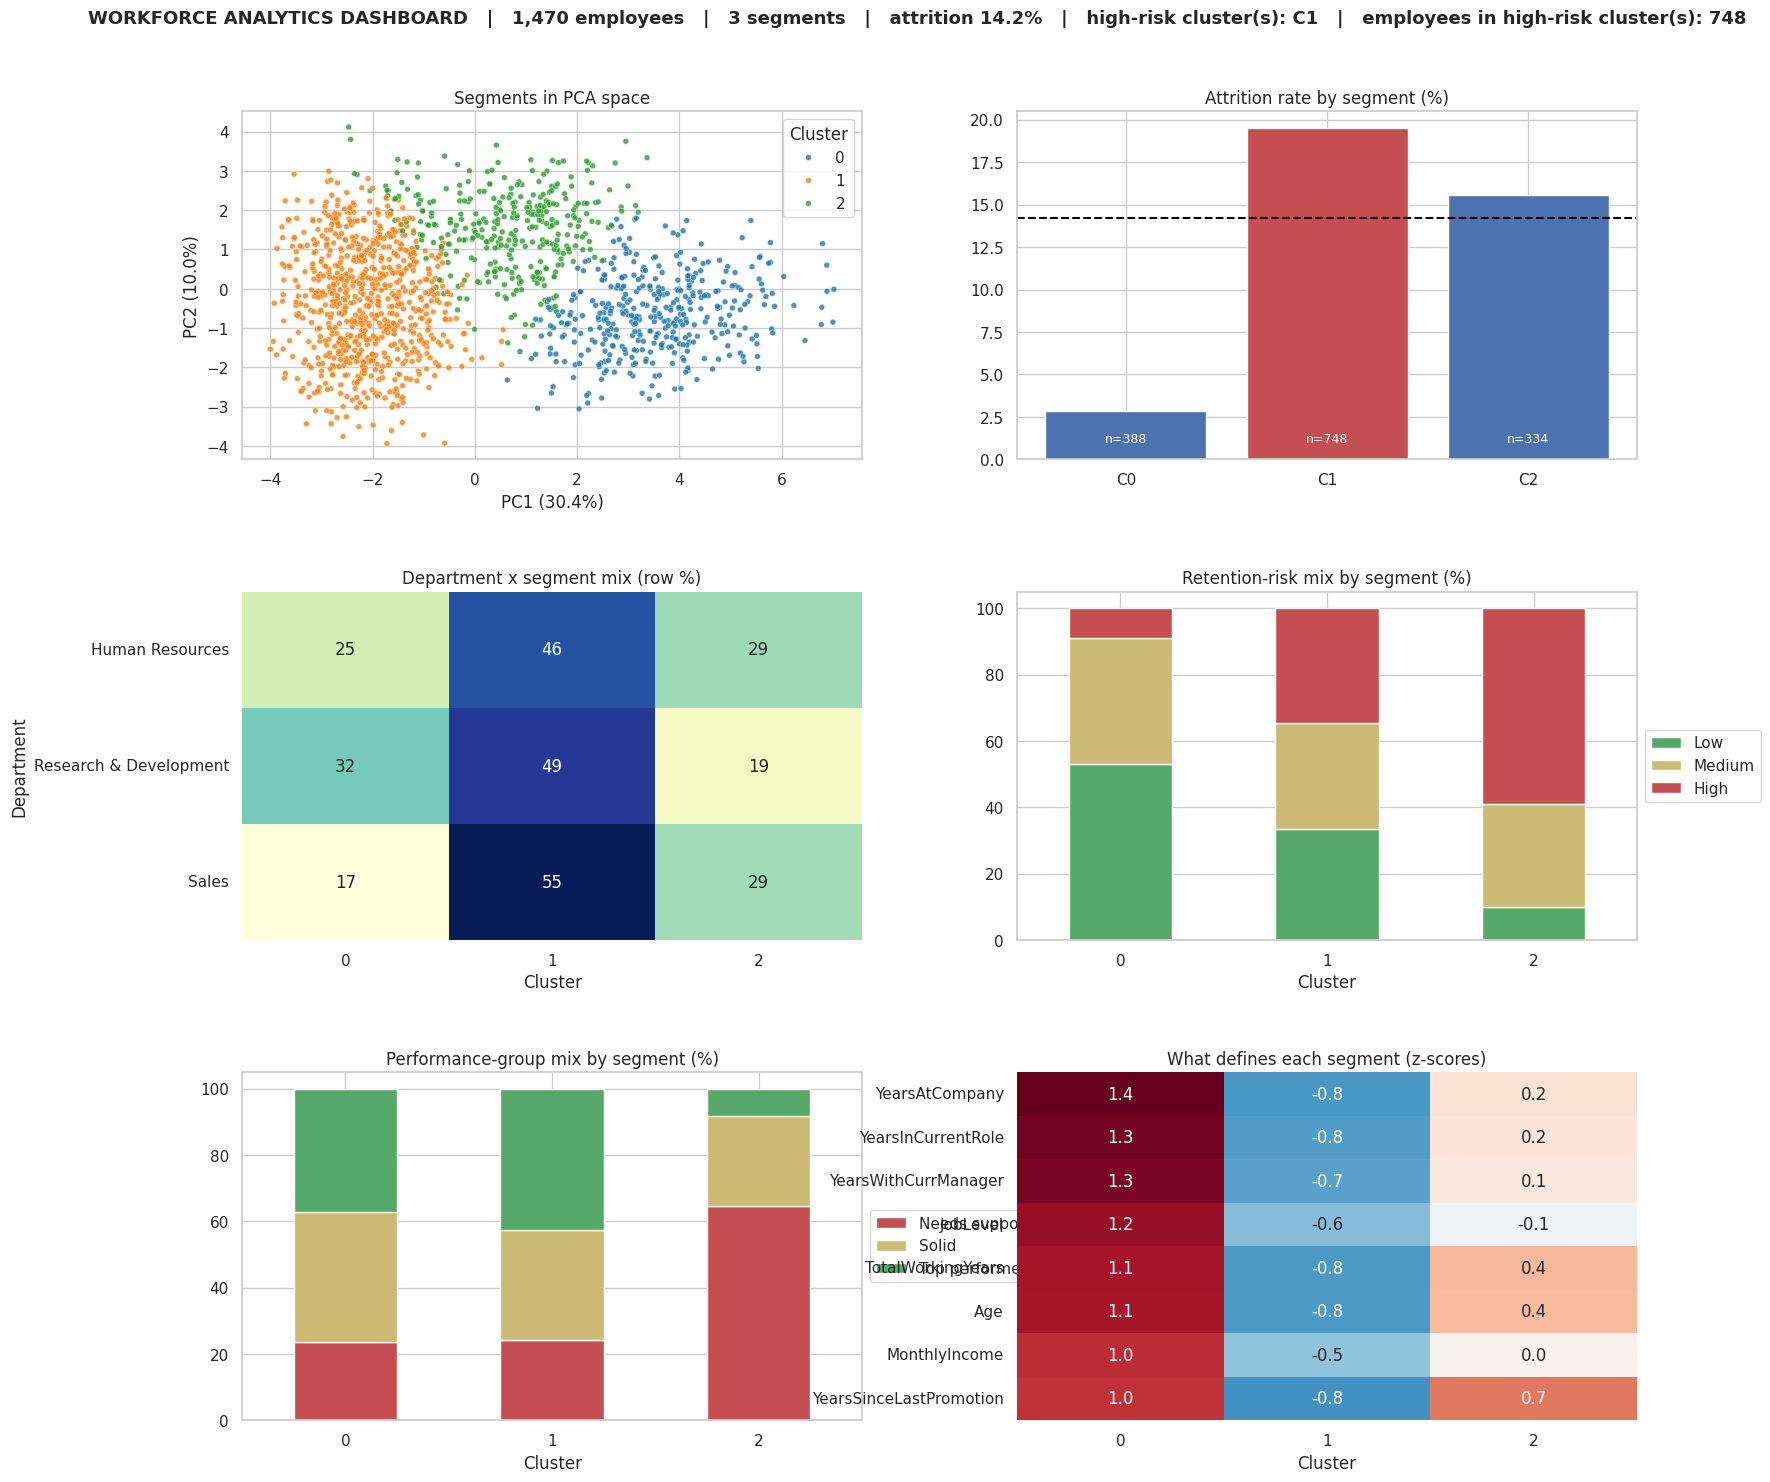

In [18]:
n_high = int(dm["Cluster"].isin(high_risk_clusters).sum())
fig = plt.figure(figsize=(18, 17))
gs = fig.add_gridspec(3, 2, hspace=.38, wspace=.25)
fig.suptitle(f"WORKFORCE ANALYTICS DASHBOARD   |   {len(dm):,} employees   |   {best_k} segments   |   "
             f"attrition {overall_attr:.1%}   |   high-risk cluster(s): {', '.join('C'+str(c) for c in high_risk_clusters)}   |   "
             f"employees in high-risk cluster(s): {n_high}", fontsize=13, fontweight="bold", y=.94)

ax = fig.add_subplot(gs[0, 0])
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=dm["Cluster"], palette="tab10", s=18, alpha=.8, ax=ax)
ax.set_title("Segments in PCA space"); ax.set_xlabel(f"PC1 ({evr[0]*100:.1f}%)"); ax.set_ylabel(f"PC2 ({evr[1]*100:.1f}%)")

ax = fig.add_subplot(gs[0, 1])
ax.bar([f"C{c}" for c in risk_tbl.index], risk_tbl["Attrition rate"] * 100, color=colors)
ax.axhline(overall_attr * 100, ls="--", c="black"); ax.set_title("Attrition rate by segment (%)")
for i, (c, h) in enumerate(zip(risk_tbl.index, risk_tbl["Headcount"])): ax.text(i, 1, f"n={h}", ha="center", color="white", fontsize=9)

ax = fig.add_subplot(gs[1, 0])
if "Department" in dm:
    sns.heatmap(dept_mix, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax, cbar=False); ax.set_title("Department x segment mix (row %)")
else:
    ax.axis("off")

ax = fig.add_subplot(gs[1, 1])
risk_by_cluster.plot.bar(stacked=True, ax=ax, color=["#55A868", "#CCB974", "#C44E52"], rot=0)
ax.set_title("Retention-risk mix by segment (%)"); ax.legend(title="", loc="center left", bbox_to_anchor=(1, .5))

ax = fig.add_subplot(gs[2, 0])
perf_by_cluster.plot.bar(stacked=True, ax=ax, color=["#C44E52", "#CCB974", "#55A868"], rot=0)
ax.set_title("Performance-group mix by segment (%)"); ax.legend(title="", loc="center left", bbox_to_anchor=(1, .5))

ax = fig.add_subplot(gs[2, 1])
top_feats = Zprof.abs().max().sort_values(ascending=False).head(8).index
sns.heatmap(Zprof[top_feats].T, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax, cbar=False)
ax.set_title("What defines each segment (z-scores)"); ax.set_xlabel("Cluster")

dash_path = savefig("workforce_dashboard.png"); plt.show()

## 9. Export Deliverables
Writes the PCA summary CSV, segmented employee file and a self-contained **HTML report** (open in a browser → *Print ▸ Save as PDF* to submit as PDF).

In [19]:
pca_summary.to_csv(f"{OUTPUT_DIR}/pca_summary.csv", index=False)
loadings.round(3).to_csv(f"{OUTPUT_DIR}/pca_loadings.csv")
seg_summary.round(3).to_csv(f"{OUTPUT_DIR}/segment_summary.csv")
dm.drop(columns=["Segment"]).assign(Segment=dm["Segment"]).to_csv(f"{OUTPUT_DIR}/employees_segmented.csv", index=False)

def img(name, width="100%"):
    with open(os.path.join(OUTPUT_DIR, name), "rb") as f:
        return f'<img src="data:image/png;base64,{base64.b64encode(f.read()).decode()}" style="width:{width}">'

def tbl(d, **kw): return d.to_html(classes="tbl", border=0, **kw)

ACTIONS = {
    ("OverTime_flag", "High"): "review workload and overtime policy; add capacity or comp-time",
    ("YearsSinceLastPromotion", "High"): "audit promotion/career-path stagnation; set development plans",
    ("JobSatisfaction", "Low"): "targeted engagement surveys and manager check-ins",
    ("WorkLifeBalance", "Low"): "flexible-work options and workload balancing",
    ("EnvironmentSatisfaction", "Low"): "address team/work-environment issues raised in surveys",
    ("MonthlyIncome", "Low"): "benchmark compensation against market",
    ("JobLevel", "Low"): "clarify progression routes from entry level",
    ("StockOptionLevel", "Low"): "consider equity / long-term incentive eligibility",
    ("BusinessTravel_ord", "High"): "reduce travel burden or add travel recovery time",
    ("JobInvolvement", "Low"): "improve role design, autonomy and ownership",
    ("NumCompaniesWorked", "High"): "invest early in onboarding and belonging (job-hopper profile)",
}

rec_html = ""
for c in high_risk_clusters:
    drv = Zprof.loc[c].sort_values(key=abs, ascending=False).head(5)
    acts = [ACTIONS[(f, "High" if v > 0 else "Low")] for f, v in drv.items() if (f, "High" if v > 0 else "Low") in ACTIONS][:3]
    rec_html += (f"<li><b>Cluster {c}</b> ({int(risk_tbl.loc[c, 'Headcount'])} employees, attrition {risk_tbl.loc[c, 'Attrition rate']:.1%}, "
                 f"{risk_tbl.loc[c, 'Attrition lift vs avg']:.2f}x average). Key drivers: "
                 + ", ".join(f"{'high' if v > 0 else 'low'} {f}" for f, v in drv.head(4).items())
                 + (". Suggested actions: " + "; ".join(acts) + "." if acts else ".") + "</li>")

best_sil_method = comparison["Silhouette"].idxmax()
data_note = ("a <b>synthetic demonstration dataset</b> (IBM-HR-style), so figures illustrate the method rather than a real company"
             if DATA_SOURCE == "synthetic" else "the uploaded HR dataset")

html = f'''<!DOCTYPE html><html><head><meta charset="utf-8"><title>Employee Segmentation Report</title>
<style>
body{{font-family:Segoe UI,Arial,sans-serif;max-width:980px;margin:30px auto;padding:0 20px;color:#222;line-height:1.55}}
h1{{border-bottom:3px solid #4C72B0;padding-bottom:8px}} h2{{color:#2c4a7c;margin-top:36px}}
.tbl{{border-collapse:collapse;font-size:13px;margin:10px 0}} .tbl th,.tbl td{{border:1px solid #ccc;padding:5px 9px;text-align:right}}
.tbl th{{background:#eef2f8}} .kpi{{display:flex;gap:14px;flex-wrap:wrap}} .kpi div{{background:#eef2f8;border-radius:8px;padding:10px 16px}}
.kpi b{{font-size:22px;display:block}} img{{margin:10px 0}} .note{{background:#fff8e1;border-left:4px solid #f0b429;padding:8px 14px}}
</style></head><body>
<h1>Employee Workforce Segmentation Report</h1>
<p class="note">Analysis performed on {data_note}.</p>

<h2>1. Executive summary</h2>
<div class="kpi"><div><b>{len(dm):,}</b>employees</div><div><b>{overall_attr:.1%}</b>overall attrition</div>
<div><b>{best_k}</b>workforce segments</div><div><b>{N_COMP}</b>PCA components ({cum[N_COMP-1]*100:.0f}% variance)</div>
<div><b>{', '.join('C'+str(c) for c in high_risk_clusters)}</b>high-risk cluster(s)</div></div>
<ul>
<li>{len(features)} HR features were reduced to {N_COMP} principal components, then segmented with K-Means and Ward hierarchical clustering (k={best_k}, chosen by silhouette).</li>
<li>The two methods agree with an Adjusted Rand Index of {ari:.2f}; the higher silhouette was obtained by <b>{best_sil_method}</b>.</li>
<li>Segments differ significantly in attrition (chi-square p = {p_val:.2g}).</li>
<li>An independent Retention Risk Index (built without the attrition label) achieves ROC-AUC {auc:.2f}; the "High" group leaves at {risk_groups.loc['High','Attrition_rate']:.1%} vs {risk_groups.loc['Low','Attrition_rate']:.1%} for "Low".</li>
</ul>

<h2>2. Data and method</h2>
<p>Features: {', '.join(features)}. Income was log-transformed, categorical fields encoded, and all features standardised. <i>Attrition was excluded from clustering</i> and used only to validate segment risk.</p>
{img("01_eda.png")}

<h2>3. PCA summary</h2>
<p>{N_COMP} components explain {cum[N_COMP-1]*100:.1f}% of the variance. First components are driven by: {'; '.join(f"<b>{pc}</b>: " + ', '.join(f for f in fs[:4]) for pc, fs in top_loadings.items())}.</p>
{tbl(pca_summary.head(8), index=False)}
{img("02_pca_variance.png")}{img("03_pca_loadings.png", "70%")}

<h2>4. Clustering results</h2>
{tbl(k_table.round(3))}
<p>Selected k = {best_k}.</p>
{img("04_k_selection.png")}{img("05_dendrogram.png")}
{tbl(comparison)}
{img("06_pca_clusters.png")}

<h2>5. Segment profiles</h2>
{tbl(seg_summary.round(2))}
{img("07_segment_fingerprint.png")}

<h2>6. High-risk employee clusters</h2>
{img("08_attrition_by_cluster.png", "60%")}
<ul>{rec_html}</ul>

<h2>7. Department-level segments</h2>
{tbl(dept_summary.round(3)) if "Department" in dm else "<p>No department data.</p>"}
{img("09_department_mix.png", "65%") if "Department" in dm else ""}

<h2>8. Performance groups</h2>
{tbl(perf_attr.round(3))}
<p>{top_perf_loss} top performers left the company (regretted attrition).</p>
{img("10_performance_groups.png")}

<h2>9. Retention-risk groups</h2>
{tbl(risk_groups.round(3))}
{img("11_retention_risk.png")}

<h2>10. Workforce analytics dashboard</h2>
{img("workforce_dashboard.png")}

<h2>11. Limitations</h2>
<ul><li>Clusters are descriptive, not causal; validate drivers with HR before acting.</li>
<li>Segment names are auto-generated from the most distinctive features.</li>
<li>Re-run periodically; segments drift as the workforce changes.</li>
<li>Use results at group level and follow privacy / fairness policies - do not use segment membership alone for individual employment decisions.</li></ul>
</body></html>'''

with open(f"{OUTPUT_DIR}/Employee_Segmentation_Report.html", "w", encoding="utf-8") as f:
    f.write(html)
print("Saved:", sorted(os.listdir(OUTPUT_DIR)))

Saved: ['01_eda.png', '02_pca_variance.png', '03_pca_loadings.png', '04_k_selection.png', '05_dendrogram.png', '06_pca_clusters.png', '07_segment_fingerprint.png', '08_attrition_by_cluster.png', '09_department_mix.png', '10_performance_groups.png', '11_retention_risk.png', 'Employee_Segmentation_Report.html', 'employees_segmented.csv', 'pca_loadings.csv', 'pca_summary.csv', 'segment_summary.csv', 'workforce_dashboard.png']


In [20]:
# Download everything as a zip (Colab) - ignored elsewhere
import shutil
shutil.make_archive("workforce_segmentation_outputs", "zip", OUTPUT_DIR)
try:
    from google.colab import files
    files.download("workforce_segmentation_outputs.zip")
except Exception:
    print("Zip saved as workforce_segmentation_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>